# Olist: анализ бразильского маркетплейса

Данные: [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce), около 100 тысяч заказов за 2016-2018 годы, загружены в PostgreSQL.

**Вопросы:**
1. Насколько можно доверять данным и что с ними не так?
2. Как менялись заказы и выручка?
3. Возвращаются ли клиенты?
4. Как сроки доставки влияют на оценку покупателя?
5. Какие сегменты клиентов есть (RFM)?
6. Насколько выручка зависит от крупных продавцов?

Все расчёты сделаны на SQL, запросы лежат в папке [`sql/`](../sql). Этот ноутбук забирает результаты из базы, строит графики и выгружает таблицы для дашборда.

## Подключение к базе

Пароль не хранится в коде. Ноутбук берёт его из переменной окружения `PG_PASSWORD` (можно положить в файл `.env` рядом с проектом, он не попадает в git). Если переменной нет, пароль спросят при запуске.

In [57]:
import os
import re
from pathlib import Path
from getpass import getpass

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sqlalchemy import create_engine, text

try:
    from dotenv import load_dotenv
    load_dotenv(Path("..") / ".env")
except ImportError:
    pass

DB = {
    "user": "postgres",
    "host": "localhost",
    "port": 5433,
    "dbname": "olist_analytics",
}
password = os.getenv("PG_PASSWORD") or getpass("Пароль PostgreSQL: ")
engine = create_engine(
    f"postgresql+psycopg2://{DB['user']}:{password}@{DB['host']}:{DB['port']}/{DB['dbname']}"
)

with engine.connect() as conn:
    print(conn.execute(text("SELECT version()")).scalar())

PostgreSQL 18.6 on x86_64-windows, compiled by msvc-19.44.35228, 64-bit


Запросы хранятся в `.sql` файлах, каждый помечен строкой `-- name: имя_запроса`. Функция ниже читает все файлы и позволяет вызвать любой запрос по имени: `q("delivery_vs_review")`. Так SQL живёт в одном месте, а ноутбук его только использует.

In [58]:
SQL_DIR = Path("..") / "sql"
IMAGES = Path("..") / "images"
EXPORTS = Path("..") / "data" / "exports"
IMAGES.mkdir(exist_ok=True)
EXPORTS.mkdir(parents=True, exist_ok=True)


def load_queries(folder):
    queries = {}
    for path in sorted(folder.glob("*.sql")):
        parts = re.split(r"^-- name: (\w+)\s*$", path.read_text(encoding="utf-8"), flags=re.M)
        for name, body in zip(parts[1::2], parts[2::2]):
            queries[name] = body.strip()
    return queries


QUERIES = load_queries(SQL_DIR)


def q(name):
    """Выполнить именованный запрос и вернуть DataFrame."""
    return pd.read_sql(text(QUERIES[name]), engine)


print(f"Загружено запросов: {len(QUERIES)}")
print(", ".join(QUERIES))

Загружено запросов: 21
orders_mart, mart_check, dq_overview, dq_orders_without_items, dq_issues, dq_orders_by_month_all, monthly_orders_growth, monthly_revenue_cumulative, avg_check, weekday_orders, repeat_customers_naive, repeat_customers_real, days_to_return, new_customers_by_month, delivery_status_share, delivery_time_stats, delivery_vs_review, days_late_vs_review, rfm_segments, sellers_pareto_curve, sellers_pareto_summary


Витрина `orders_mart` (одна строка = один заказ) уже создана в базе. Ячейка ниже пересоздаёт её из `sql/00_orders_mart.sql`, чтобы проект можно было воспроизвести с нуля. `engine.begin()` открывает транзакцию: если что-то пойдёт не так, изменения откатятся.

In [59]:
with engine.begin() as conn:
    conn.execute(text(QUERIES["orders_mart"]))

q("mart_check")

,rows_count,unique_orders
0,99441,99441


In [60]:
# общий стиль графиков
BLUE   = "#9964e8"  
ORANGE = "#ec749b"  
GRAY   = "#8c8b85"  

plt.rcParams.update({
    "figure.dpi": 100,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.size": 10,
    "text.color": "#3a3a3a",
    "axes.labelcolor": "#555555",
    "xtick.color": "#666666",
    "ytick.color": "#666666",
    "axes.titlesize": 12,
    "axes.titleweight": "normal",
    "axes.titlepad": 12,
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.edgecolor": "#d6d6d6",
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#ececec",
    "grid.linewidth": 0.5,
    "axes.axisbelow": True,
    "lines.linewidth": 2,
    "lines.markersize": 5,
    "patch.edgecolor": "none",
    "legend.frameon": False,
})


def save(fig, name):
    fig.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Качество данных

In [61]:
q("dq_overview").T

,0
orders,99441
customer_ids,99441
unique_customers,96096
order_items,112650
reviews,99224
products,32951
first_order,2016-09-04 21:15:19
last_order,2018-10-17 17:30:18


Заказов 99 441, а `customer_id` столько же: это **не клиент, а ID клиента в конкретном заказе**. Реальный человек - `customer_unique_id`, их 96 096. Все расчёты по клиентам дальше идут по нему.

In [62]:
q("dq_orders_without_items")

,order_status,orders
0,unavailable,603
1,canceled,164
2,created,5
3,invoiced,2
4,shipped,1


In [63]:
q("dq_issues")

,issue,cnt
0,товары без категории,610
1,доставленные заказы без даты доставки,8
2,заказы без отзыва,768
3,заказы с несколькими отзывами,547


Что нашлось:
- **775 заказов без товаров**, 97% из них со статусами `unavailable` и `canceled`: заказ не собрали или отменили, и позиции не записались. Для расчёта выручки они бесполезны.
- **768 заказов без отзыва**.
- **8 «доставленных» заказов без даты доставки** - ошибка в данных.
- **610 товаров без категории**.
- **547 заказов с несколькими отзывами.** Причины разные: заказ пришёл несколькими посылками, и на каждую был отдельный опрос; клиент изменил мнение (например, сначала 5, через неделю 1); технические дубли. Везде дальше берётся **последний отзыв** по дате.

Выручку и доставку считаем только по заказам со статусом `delivered`.

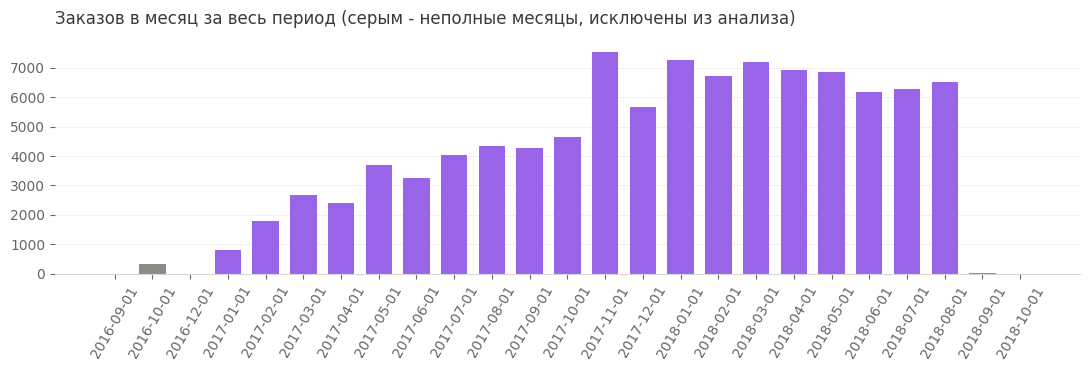

In [64]:
months_all = q("dq_orders_by_month_all")
in_window = (months_all["month"] >= pd.Timestamp("2017-01-01").date()) & (months_all["month"] < pd.Timestamp("2018-09-01").date())

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(months_all["month"].astype(str), months_all["orders"],
       color=[BLUE if w else GRAY for w in in_window], width=0.7)
ax.set_title("Заказов в месяц за весь период (серым - неполные месяцы, исключены из анализа)")
ax.tick_params(axis="x", rotation=60)
ax.grid(axis="x", visible=False)
plt.tight_layout()
save(fig, "orders_by_month_all")
plt.show()

В начале (2016) маркетплейс только запускался, а в сентябре-октябре 2018 данные обрываются: это конец выгрузки, а не падение продаж. Ноября 2016 в данных нет совсем. Поэтому динамику смотрим на периоде **январь 2017 - август 2018** (20 полных месяцев).

## 2. Заказы и выручка

In [65]:
growth = q("monthly_orders_growth")
revenue = q("monthly_revenue_cumulative")
growth

,month,orders,prev_orders,growth_pct
0,2017-01-01,800,NaN,NaN
1,2017-02-01,1780,800.0,122.5
2,2017-03-01,2682,1780.0,50.7
3,2017-04-01,2404,2682.0,-10.4
4,2017-05-01,3700,2404.0,53.9
5,2017-06-01,3245,3700.0,-12.3
6,2017-07-01,4026,3245.0,24.1
7,2017-08-01,4331,4026.0,7.6
8,2017-09-01,4285,4331.0,-1.1
9,2017-10-01,4631,4285.0,8.1


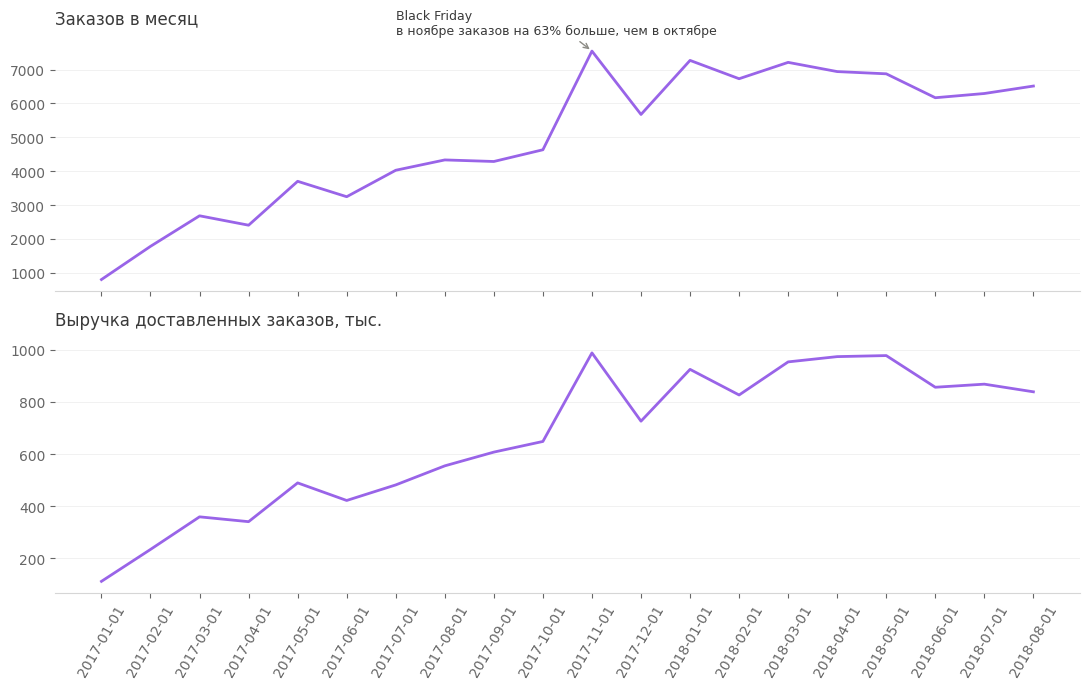

In [83]:
monthly = growth.merge(revenue[["month", "revenue"]], on="month", how="left")
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
months = monthly["month"].astype(str)

axes[0].plot(months, growth["orders"], color=BLUE, lw=2, ms=5)
axes[0].set_title("Заказов в месяц")
bf = growth.index[growth["month"].astype(str) == "2017-11-01"]
if len(bf):
    i = bf[0]
    axes[0].annotate(f"Black Friday\nв ноябре заказов на {growth.loc[i, 'growth_pct']:.0f}% больше, чем в октябре",
                     xy=(i, growth.loc[i, "orders"]), xytext=(i - 4, growth.loc[i, "orders"] + 500),
                     arrowprops=dict(arrowstyle="->", color=GRAY), fontsize=9)

axes[1].plot(months, monthly["revenue"] / 1000, color=BLUE, lw=2, ms=5)
axes[1].set_title("Выручка доставленных заказов, тыс.")
axes[1].tick_params(axis="x", rotation=60)
plt.tight_layout()
save(fig, "orders_revenue_by_month")
plt.show()

In [67]:
revenue

,month,revenue,cumulative_revenue,month_share_pct,cumulative_share_pct
0,2017-01-01,111798.0,111798.0,0.8,0.8
1,2017-02-01,234223.0,346022.0,1.8,2.6
2,2017-03-01,359199.0,705221.0,2.7,5.4
3,2017-04-01,340670.0,1045890.0,2.6,7.9
4,2017-05-01,489338.0,1535229.0,3.7,11.6
5,2017-06-01,421923.0,1957152.0,3.2,14.8
6,2017-07-01,481605.0,2438756.0,3.7,18.5
7,2017-08-01,554700.0,2993456.0,4.2,22.7
8,2017-09-01,607400.0,3600856.0,4.6,27.3
9,2017-10-01,648248.0,4249103.0,4.9,32.2


- Число заказов росло весь 2017 год и вышло на плато около 6-7 тысяч в месяц в 2018-м.
- **Ноябрь 2017 (Black Friday): +62.9% заказов к октябрю**, а в декабре −24.8%: после распродажи спрос проседает.
- К концу 2017 года набрано около 45% выручки периода, **55% пришлось на 8 месяцев 2018 года**.

In [68]:
q("avg_check")

,avg_check,median_check,above_avg_pct
0,137.75,86.9,29.3


Средний чек 137.75, а медиана 86.9, и выше среднего только около 29% заказов: большинство покупок недорогие, а среднее тянут вверх редкие дорогие заказы. Для отчётов честнее показывать медиану.

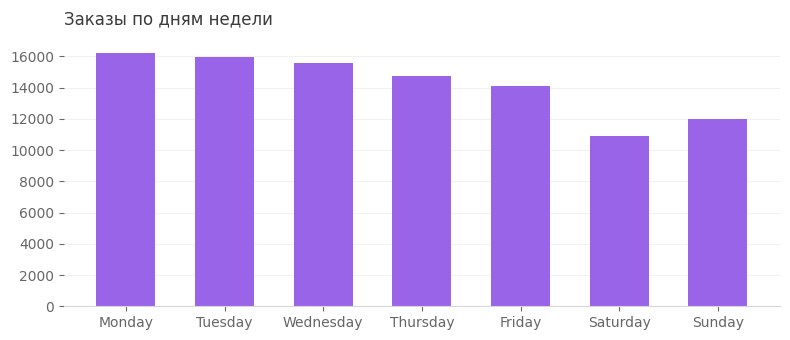

In [69]:
weekday = q("weekday_orders")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(weekday["weekday"], weekday["orders"], color=BLUE, width=0.6)
ax.set_title("Заказы по дням недели")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

Больше всего покупают в понедельник, к выходным заказов становится меньше, минимум - суббота.

## 3. Возвращаются ли клиенты

In [70]:
q("repeat_customers_naive")

,all_clients,repeat_clients,repeat_pct
0,96096,2997,3.12


In [71]:
q("repeat_customers_real")

,same_day_orders,real_returns,real_repeat_customers,real_repeat_pct
0,961,2384,2149,2.24


По `customer_unique_id` повторную покупку сделали **3.1%** клиентов. Но 961 «повторный» заказ сделан в **тот же день**, что и предыдущий, иногда с разницей в секунды: это корзина, которую система разбила на несколько заказов, а не возврат. **Настоящих повторных покупателей около 2.2%.**

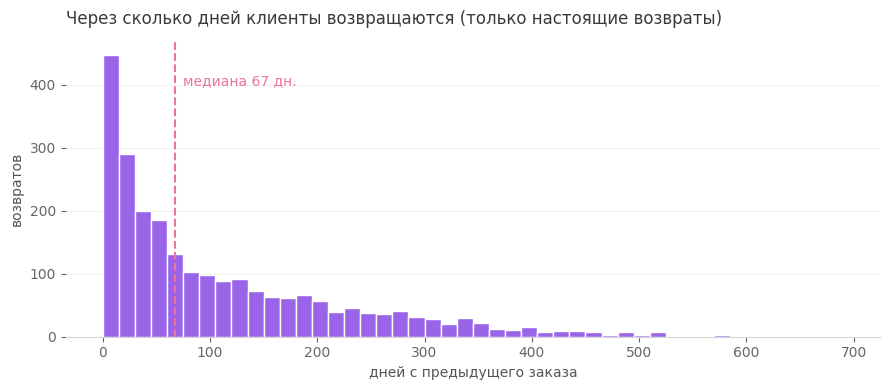

среднее 110 дн., медиана 67 дн.


In [72]:
days = q("days_to_return")["days_since_prev"]
median_days = days.median()

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(days, bins=range(0, 700, 15), color=BLUE, edgecolor="white")
ax.axvline(median_days, color=ORANGE, ls="--", lw=1.5)
ax.text(median_days + 8, ax.get_ylim()[1] * 0.85, f"медиана {median_days:.0f} дн.", color=ORANGE)
ax.set_title("Через сколько дней клиенты возвращаются (только настоящие возвраты)")
ax.set_xlabel("дней с предыдущего заказа")
ax.set_ylabel("возвратов")
plt.tight_layout()
save(fig, "days_to_return")
plt.show()

print(f"среднее {days.mean():.0f} дн., медиана {median_days:.0f} дн.")

Если клиент возвращается, то обычно через 2-3 месяца (медиана 67 дней). Среднее больше (около 110 дней) из-за тех, кто вернулся через год и позже.

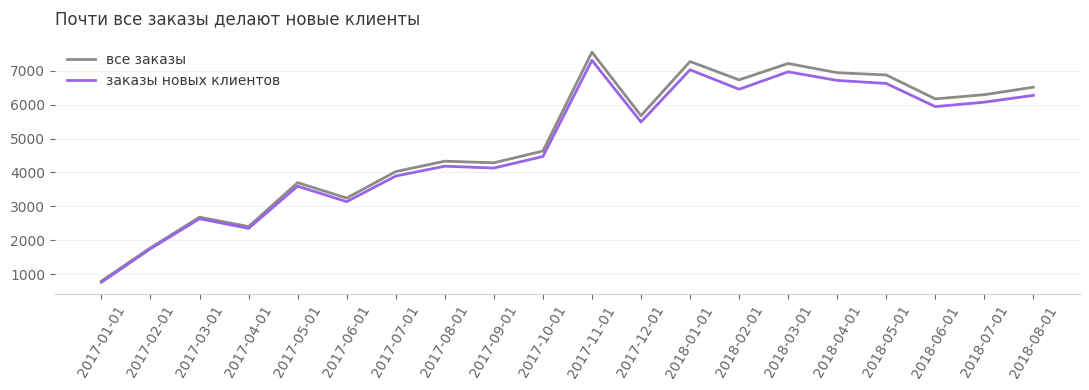

count    20.000000
mean     96.740000
std       0.712593
min      95.500000
25%      96.375000
50%      96.600000
75%      96.725000
max      98.400000
Name: new_share_pct, dtype: float64

In [73]:
newc = q("new_customers_by_month")
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(newc["month"].astype(str), newc["all_orders"], color=GRAY, lw=2, label="все заказы")
ax.plot(newc["month"].astype(str), newc["new_customers"], color=BLUE, lw=2, label="заказы новых клиентов")
ax.set_title("Почти все заказы делают новые клиенты")
ax.tick_params(axis="x", rotation=60)
ax.legend(frameon=False)
plt.tight_layout()
save(fig, "new_customers")
plt.show()

newc["new_share_pct"].describe()

Каждый месяц около 96-97% заказов приходится на новых клиентов. Рост Olist держится на привлечении, а не на удержании.

## 4. Доставка и отзывы

In [74]:
q("delivery_status_share")

,delivery_status,orders,share_pct
0,вовремя,88644,91.9
1,опоздание,7826,8.1
2,нет даты,8,0.0


In [75]:
q("delivery_time_stats")

,avg_delivery_days,avg_days_late_among_late
0,12.6,9.6


In [76]:
dvr = q("delivery_vs_review")
dvr

,is_late,orders,avg_score,neg_pct
0,on_time,88644,4.29,9.2
1,late,7826,2.57,54.1


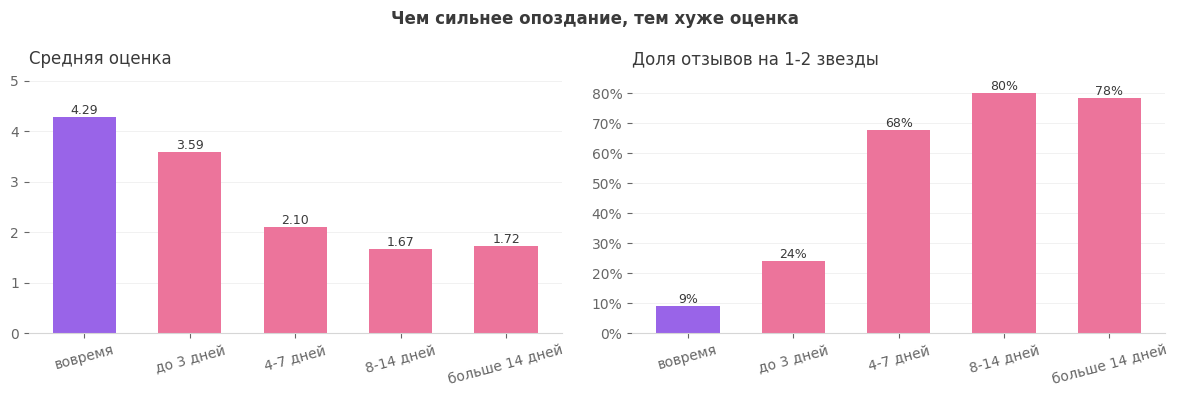

,lateness,orders,avg_score,neg_pct
0,0. вовремя,88644,4.29,9.2
1,1. до 3 дней,3162,3.59,24.1
2,2. 4-7 дней,1802,2.10,67.7
3,3. 8-14 дней,1478,1.67,80.2
4,4. больше 14 дней,1384,1.72,78.4


In [77]:
late = q("days_late_vs_review")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
labels = late["lateness"].str.split(". ", n=1).str[1]
axes[0].bar(labels, late["avg_score"], color=[BLUE] + [ORANGE] * (len(late) - 1), width=0.6)
axes[0].set_title("Средняя оценка")
axes[0].set_ylim(0, 5)
axes[1].bar(labels, late["neg_pct"], color=[BLUE] + [ORANGE] * (len(late) - 1), width=0.6)
axes[1].set_title("Доля отзывов на 1-2 звезды")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(100))
for ax, col, fmt in [(axes[0], "avg_score", "{:.2f}"), (axes[1], "neg_pct", "{:.0f}%")]:
    for x, v in enumerate(late[col]):
        ax.text(x, v, fmt.format(v), ha="center", va="bottom", fontsize=9)
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", rotation=15)
fig.suptitle("Чем сильнее опоздание, тем хуже оценка", fontweight="bold")
plt.tight_layout()
save(fig, "lateness_vs_review")
plt.show()

late

- 91.9% заказов доставлены вовремя, 8.1% - с опозданием. Доставка в среднем занимает около 12.6 дней, а опоздавшие заказы приходят в среднем на 9.6 дня позже обещанного.
- **Опоздание - главный фактор плохих отзывов.** Средняя оценка падает с 4.29 до 2.57, а доля отзывов на 1-2 звезды растёт с 9% до 54%, почти в 6 раз.
- Важна длина опоздания. При опоздании до 3 дней плохих отзывов 24%, при 4-7 днях уже 68%, а после недели около 80% и дальше почти не растёт. Главное - не допускать опозданий больше 3 дней.

**Что можно сделать:** точнее обещать срок доставки и разбираться с логистикой там, где опоздания чаще.

## 5. RFM-сегментация

Давность (R) и сумма покупок (M) разбиты на 5 групп через `NTILE(5)`. Частоту (F) через `NTILE` считать бессмысленно, потому что у ~97% клиентов один заказ, поэтому F = «1 заказ» или «больше». По сути сегментация здесь держится на R и M.

In [78]:
rfm = q("rfm_segments")
rfm

,seg,customers,pct,avg_monetary,avg_recency_days
0,потерянные,40617,43.51,88.52,316.0
1,новые,21672,23.21,55.49,89.0
2,лучшие,15400,16.50,271.22,90.0
3,уходящие,14529,15.56,279.02,393.0
4,повторные,1140,1.22,168.96,225.0


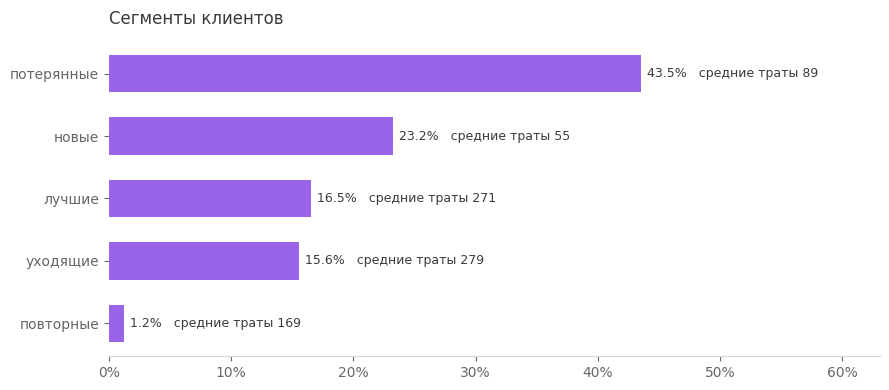

In [79]:
fig, ax = plt.subplots(figsize=(9, 4))
r = rfm.sort_values("pct")
ax.barh(r["seg"], r["pct"], color=BLUE, height=0.6)
for y, (p, m) in enumerate(zip(r["pct"], r["avg_monetary"])):
    ax.text(p + 0.5, y, f"{p:.1f}%   средние траты {m:.0f}", va="center", fontsize=9)
ax.set_title("Сегменты клиентов")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(100))
ax.set_xlim(0, r["pct"].max() * 1.45)
ax.grid(axis="y", visible=False)
plt.tight_layout()
save(fig, "rfm_segments")
plt.show()

| Сегмент | Кто это | Что делать |
|---|---|---|
| лучшие | купили недавно и много | удерживать: программа лояльности |
| уходящие | потратили много, но давно | вернуть персональным предложением |
| новые | купили недавно, но мало | подтолкнуть ко второй покупке через 1-2 месяца |
| повторные | покупали больше одного раза | беречь, это самая редкая группа |
| потерянные | давно и мало | не тратить на них бюджет |

## 6. Продавцы: правило Парето

In [80]:
q("sellers_pareto_summary")

,all_sellers,sellers_for_80pct,sellers_for_80pct_share
0,2945,530,18.0


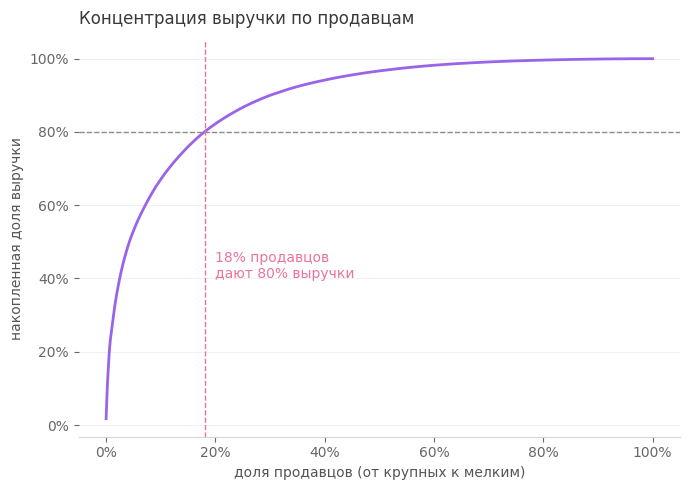

In [81]:
curve = q("sellers_pareto_curve")
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(curve["sellers_pct"], curve["cumulative_revenue_pct"], color=BLUE, lw=2)
ax.axhline(80, color=GRAY, ls="--", lw=1)
x80 = curve.loc[curve["cumulative_revenue_pct"] >= 80, "sellers_pct"].iloc[0]
ax.axvline(x80, color=ORANGE, ls="--", lw=1)
ax.text(x80 + 2, 40, f"{x80:.0f}% продавцов\nдают 80% выручки", color=ORANGE)
ax.set_xlabel("доля продавцов (от крупных к мелким)")
ax.set_ylabel("накопленная доля выручки")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(100))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(100))
ax.set_title("Концентрация выручки по продавцам")
plt.tight_layout()
save(fig, "sellers_pareto")
plt.show()

Около 18% продавцов (530 из 2 945) приносят 80% выручки. Уход даже нескольких крупных продавцов заметно ударит по маркетплейсу, поэтому их стоит выделять в отдельную группу и удерживать.

## 7. Выгрузка для дашборда

Таблицы для Yandex DataLens: локальная база недоступна из интернета, поэтому результаты выгружаются в CSV и загружаются в DataLens как файлы.

In [82]:
exports = {
    "orders_mart": pd.read_sql(text("SELECT * FROM orders_mart"), engine),
    "monthly_revenue": revenue,
    "monthly_orders": growth,
    "rfm_segments": rfm,
    "lateness_vs_review": late,
}
for name, df in exports.items():
    df.to_csv(EXPORTS / f"{name}.csv", index=False)
    print(f"{name}: {len(df)} строк")

orders_mart: 99441 строк
monthly_revenue: 20 строк
monthly_orders: 20 строк
rfm_segments: 5 строк
lateness_vs_review: 5 строк


## Выводы

1. **Данные:** `customer_id` - это не клиент, клиентов нужно считать по `customer_unique_id`. Найдены заказы без товаров, «доставленные» без даты, дубли отзывов. Решения о том, как их учитывать, описаны в разделе 1.
2. **Рост:** заказы росли весь 2017 год и вышли на плато в 2018-м. Black Friday дал +63% заказов за месяц.
3. **Удержание - главная проблема:** только около 2% клиентов возвращаются за второй покупкой. Те, кто возвращается, делают это примерно через 2 месяца, и в это окно стоит отправлять напоминания и промокоды.
4. **Доставка:** опоздание увеличивает долю отзывов на 1-2 звезды почти в 6 раз (54% против 9%). Это самый сильный рычаг для улучшения оценок.
5. **Продавцы:** 18% продавцов дают 80% выручки, бизнес сильно зависит от крупных продавцов.